In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## learning-curve

**Figure 1: Validation accuracy over training on CIFAR-100 for our augmentation, Mixup and the baseline.** Lines show the mean and shaded bands ±1 std over 5 seeds; thin horizontal dashed lines mark the final mean accuracy of ours and of Mixup, the strongest competitor. Ours ends at 91.2%, 1.7 points above Mixup (89.5%) and 3.4 points above the baseline (87.8%).

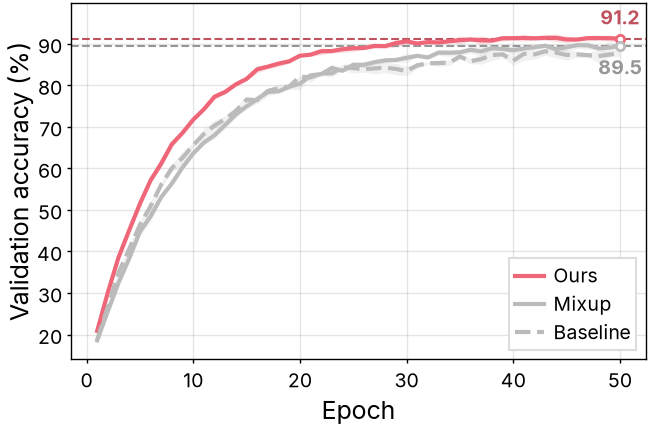

In [2]:
with open("../learning-curve.json") as f:
    data = json.load(f)
epochs = data["epochs"]

fig, ax = plt.subplots(figsize=(3.25, 2))
series = [
    ("Ours", colors["ours"], "-"),
    ("Mixup", colors["neutral"], "-"),
    ("Baseline", colors["neutral"], "--"),
]
for name, color, linestyle in series:
    runs = 100 * np.array(data["accuracy"][name])
    mean, std = runs.mean(axis=0), runs.std(axis=0)
    ax.fill_between(epochs, mean - std, mean + std, color=color, alpha=0.2, linewidth=0)
    ax.plot(epochs, mean, color=color, linestyle=linestyle, label=name)
    # the three final values are too close to label all; ours and the strongest competitor are marked
    if name == "Ours":
        mark_value(ax, epochs[-1], mean[-1], f"{mean[-1]:.1f}", color)
    if name == "Mixup":
        mark_value(ax, epochs[-1], mean[-1], f"{mean[-1]:.1f}", color, below=True)

ax.set_xlabel("Epoch")
ax.set_ylabel("Validation accuracy (%)")
ax.legend(loc="lower right")

fit_height(fig, ax, aspect=0.618)
fig.savefig("learning-curve.pdf")
fig.savefig("learning-curve.png")
plt.show()